In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# locate global_data whether Jupyter starts in this folder or a project parent.
data_dir = next(
    (candidate for parent in (Path.cwd(), *Path.cwd().parents)
     for candidate in (parent / "global_data", parent / "abraham" / "global_data")
     if (candidate / "airport_info.csv").is_file()
     and (candidate / "pax_forecasting.csv").is_file()),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Start Jupyter from the project folder or internal_data_exploration.")

# both files use pipes and include an exported row index in the first column.
airport_info = pd.read_csv(data_dir / "airport_info.csv", sep="|", index_col=0)
pax_forecasting = pd.read_csv(data_dir / "pax_forecasting.csv", sep="|", index_col=0)

print("airport_info — first 10 rows:")
display(airport_info.head(10))

print("pax_forecasting — first 10 rows:")
display(pax_forecasting.head(10))


airport_info — first 10 rows:


,AIRPRT_CD,AIRPRT_NM,CITY_METRO_IATA_CD,STATE_PROVNC_CD,CNTRY_CD,WRLD_AREA_DOT_CD,LAT_DEGREE_QTY,LAT_MINUTE_QTY,LAT_SECOND_QTY,LAT_HEMSPHR_CD,LNGTD_DEGREE_QTY,LNGTD_MINUTE_QTY,LNGTD_SECOND_QTY,LNGTD_HEMSPHR_CD,LNGST_RUNWAY_FT_QTY,ELEVATN_FT_QTY,SF_LOAD_TMS
0,OAH,Shindand Air Base,OAH,NaN,AF,701,33,23,32,N,62,15,40,E,7900,3780,2025-02-17 16:55:48.934
1,REX,Lucio Blanco Intl,REX,NaN,MX,148,26,0,30,N,98,13,41,W,6200,139,2025-02-17 16:55:48.934
2,YQX,Gander Intl.,YQX,NL,CA,961,48,56,13,N,54,34,5,W,10200,496,2025-02-17 16:55:48.934
3,MLW,Spriggs Payne,MLW,NaN,LR,537,6,17,19,N,10,45,32,W,6000,26,2025-02-17 16:55:48.934
4,CIJ,Capitan Anibal Arab,CIJ,NaN,BO,312,11,2,16,S,68,47,0,W,8500,805,2025-02-17 16:55:48.934
5,KGJ,Karonga Airport,KGJ,NaN,MW,542,9,57,12,S,33,53,35,E,5500,0,2025-02-17 16:55:48.934
6,FDF,Martinique A. Cesaire,FDF,NaN,MQ,252,14,35,32,N,60,59,47,W,9800,16,2025-02-17 16:55:48.934
7,IUE,Niue Island Intl.,IUE,NaN,NU,852,19,4,41,S,169,55,36,W,7600,211,2025-02-17 16:55:48.934
8,LTI,Altai Airport,LTI,NaN,MN,751,46,22,37,N,96,13,2,E,9500,7280,2025-02-17 16:55:48.934
9,LAP,Manuel Marquez de Leon,LAP,NaN,MX,148,24,4,21,N,110,21,45,W,8200,69,2025-02-17 16:55:48.934


pax_forecasting — first 10 rows:


,DEP_MONTH,DEP_YEAR,ORG_AIRPRT,DES_AIRPRT,OD_PAX,OD_REV_USD,SF_LOAD_TMS
0,12,2023,SAN,PVR,3609.91,562691.27,2026-09-15 22:06:11.407
1,12,2019,SAN,PVR,3271.89,533964.07,2026-09-15 22:06:11.407
2,8,2022,SAN,PVR,1435.84,167189.61,2026-09-15 22:06:11.407
3,2,2021,SAN,PVR,546.57,80287.17,2026-09-15 22:06:11.407
4,5,2021,SAN,PVR,1741.58,273545.15,2026-09-15 22:06:11.407
5,9,2019,SAN,PVR,604.22,78420.68,2026-09-15 22:06:11.407
6,12,2025,SAN,PVR,2796.52,617198.70,2026-09-15 22:06:11.407
7,4,2020,SAN,PVR,18.36,1883.88,2026-09-15 22:06:11.407
8,4,2025,SAN,PVR,1350.33,286249.36,2026-09-15 22:06:11.407
9,10,2023,SAN,PVR,1447.77,230266.90,2026-09-15 22:06:11.407


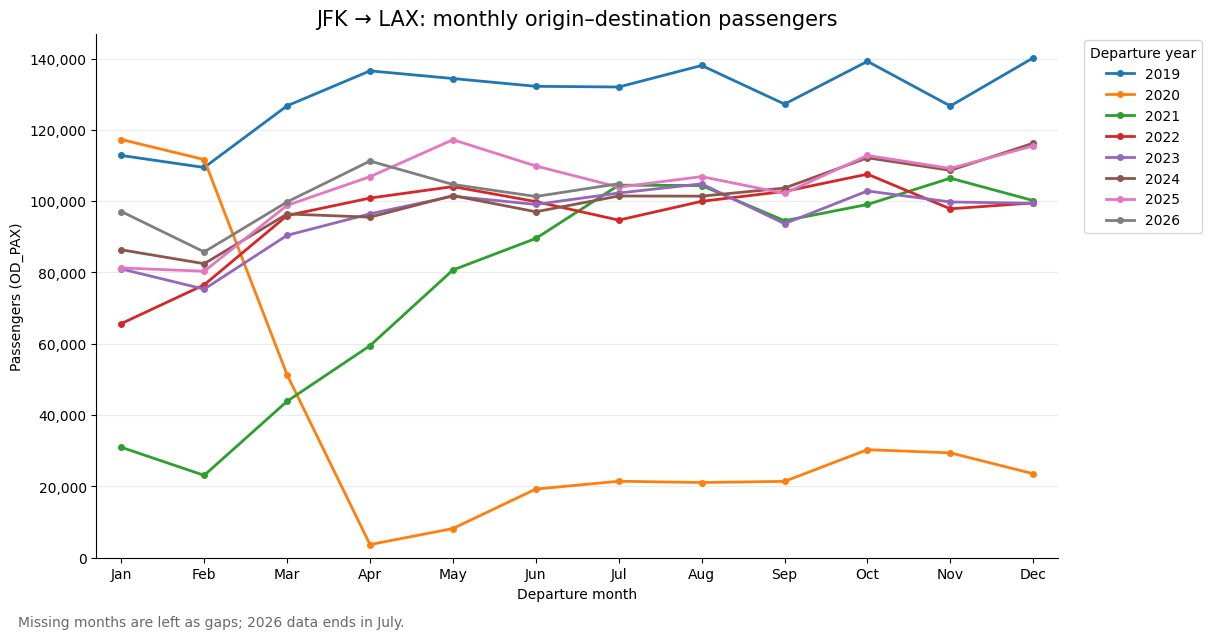

In [2]:
import calendar
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# One direction only: New York JFK to Los Angeles LAX.
origin, destination = "JFK", "LAX"
pair_data = pax_forecasting.loc[
    (pax_forecasting["ORG_AIRPRT"] == origin)
    & (pax_forecasting["DES_AIRPRT"] == destination),
    ["DEP_YEAR", "DEP_MONTH", "OD_PAX"],
].copy()

# Keep missing months as NaN: lines break at gaps instead of connecting over them.
monthly_pax = (
    pair_data.pivot(index="DEP_MONTH", columns="DEP_YEAR", values="OD_PAX")
    .reindex(index=range(1, 13))
    .sort_index(axis=1)
)

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
colors = plt.get_cmap("tab10").colors
for i, year in enumerate(monthly_pax.columns):
    ax.plot(
        monthly_pax.index, monthly_pax[year],
        color=colors[i % len(colors)], marker="o", markersize=4,
        linewidth=2, label=str(year),
    )

ax.set_title(f"{origin} → {destination}: monthly origin–destination passengers", fontsize=15)
ax.set_xlabel("Departure month")
ax.set_ylabel("Passengers (OD_PAX)")
ax.set_xticks(range(1, 13), list(calendar.month_abbr)[1:])
ax.set_xlim(0.7, 12.3)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Departure year", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.text(0.01, -0.035, "Missing months are left as gaps; 2026 data ends in July.", fontsize=10, color="dimgray")
plt.show()


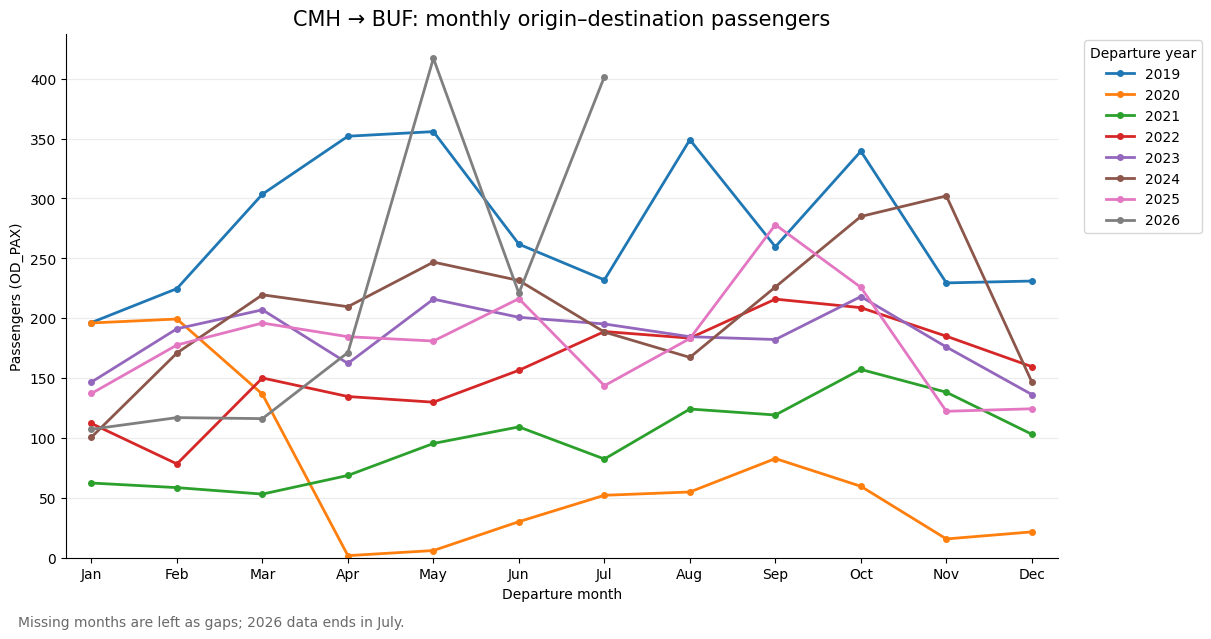

In [3]:
import calendar
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# One direction only: Columbus (CMH) to Buffalo (BUF).
# Selected near the 25th percentile of pair-level mean monthly OD_PAX,
# among pairs with all 91 observed months (about 172 passengers/month).
origin, destination = "CMH", "BUF"
pair_data = pax_forecasting.loc[
    (pax_forecasting["ORG_AIRPRT"] == origin)
    & (pax_forecasting["DES_AIRPRT"] == destination),
    ["DEP_YEAR", "DEP_MONTH", "OD_PAX"],
].copy()

# Keep missing months as NaN: lines break at gaps instead of connecting over them.
monthly_pax = (
    pair_data.pivot(index="DEP_MONTH", columns="DEP_YEAR", values="OD_PAX")
    .reindex(index=range(1, 13))
    .sort_index(axis=1)
)

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
colors = plt.get_cmap("tab10").colors
for i, year in enumerate(monthly_pax.columns):
    ax.plot(
        monthly_pax.index, monthly_pax[year],
        color=colors[i % len(colors)], marker="o", markersize=4,
        linewidth=2, label=str(year),
    )

ax.set_title(f"{origin} → {destination}: monthly origin–destination passengers", fontsize=15)
ax.set_xlabel("Departure month")
ax.set_ylabel("Passengers (OD_PAX)")
ax.set_xticks(range(1, 13), list(calendar.month_abbr)[1:])
ax.set_xlim(0.7, 12.3)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Departure year", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.text(0.01, -0.035, "Missing months are left as gaps; 2026 data ends in July.", fontsize=10, color="dimgray")
plt.show()


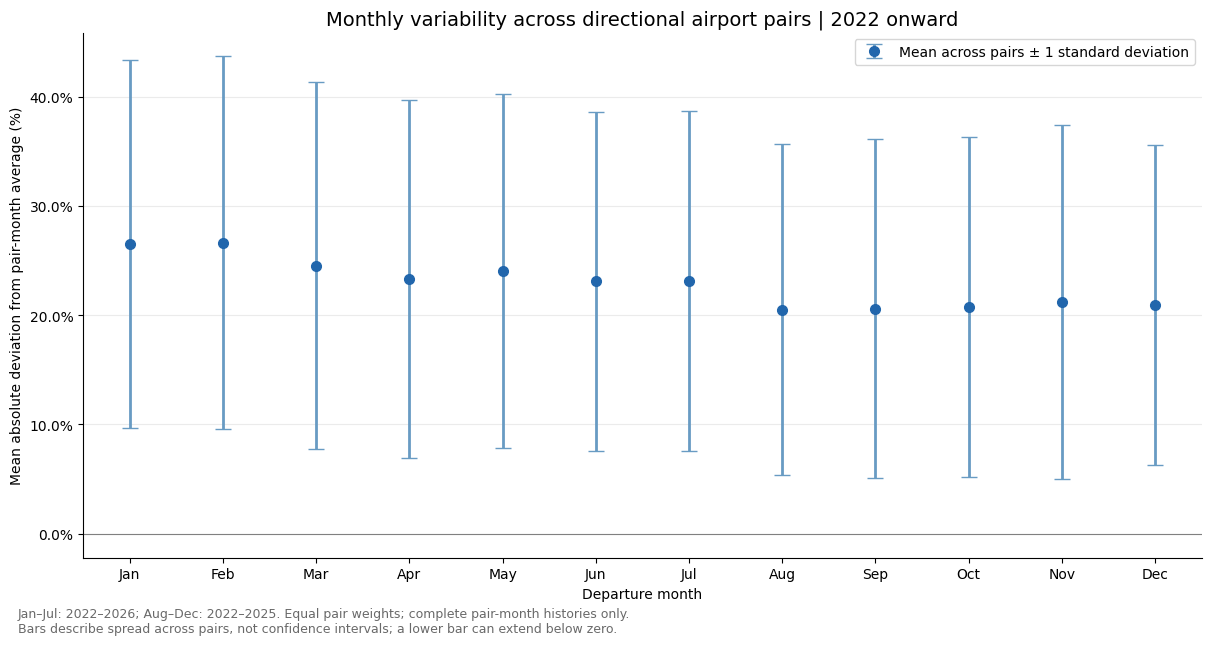

,mean_deviation_pct,std_across_pairs_pct,pair_count,years_per_pair
DEP_MONTH,,,,
1,26.49,16.85,17020,5
2,26.64,17.05,16965,5
3,24.54,16.76,17001,5
4,23.33,16.38,17005,5
5,24.07,16.20,17086,5
6,23.11,15.52,17031,5
7,23.13,15.59,17082,5
8,20.51,15.14,17083,4
9,20.58,15.52,17067,4


In [4]:
import calendar
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

# Exclude 2019, 2020, and 2021 completely.
recent_pax = pax_forecasting.loc[
    pax_forecasting["DEP_YEAR"] >= 2022,
    ["ORG_AIRPRT", "DES_AIRPRT", "DEP_YEAR", "DEP_MONTH", "OD_PAX"],
].copy()
pair_month_keys = ["ORG_AIRPRT", "DES_AIRPRT", "DEP_MONTH"]
if recent_pax.duplicated(pair_month_keys + ["DEP_YEAR"]).any():
    raise ValueError("Expected one observation per directional pair, year, and month.")

# Require every available year for a given calendar month; never fill gaps with zero.
expected_years = recent_pax.groupby("DEP_MONTH")["DEP_YEAR"].nunique()
pair_month_groups = recent_pax.groupby(pair_month_keys)
recent_pax["pair_month_mean"] = pair_month_groups["OD_PAX"].transform("mean")
recent_pax["year_count"] = pair_month_groups["DEP_YEAR"].transform("nunique")
complete = recent_pax["year_count"].eq(recent_pax["DEP_MONTH"].map(expected_years))
eligible = recent_pax.loc[
    complete & (recent_pax["pair_month_mean"] > 0)
    & (recent_pax["year_count"] >= 2)
].copy()

# For each observation: 100 * |passengers - pair/month mean| / pair/month mean.
# Absolute deviations avoid positive and negative differences cancelling out.
eligible["absolute_pct_deviation"] = (
    100 * (eligible["OD_PAX"] - eligible["pair_month_mean"]).abs()
    / eligible["pair_month_mean"]
)
pair_month_deviation = (
    eligible.groupby(pair_month_keys)["absolute_pct_deviation"]
    .mean().rename("mean_absolute_pct_deviation").reset_index()
)

# Each directional pair gets equal weight, regardless of passenger volume.
monthly_deviation_summary = (
    pair_month_deviation.groupby("DEP_MONTH")["mean_absolute_pct_deviation"]
    .agg(mean_deviation_pct="mean", std_across_pairs_pct="std", pair_count="count")
    .reindex(range(1, 13))
)
monthly_deviation_summary["years_per_pair"] = expected_years

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
ax.errorbar(
    monthly_deviation_summary.index,
    monthly_deviation_summary["mean_deviation_pct"],
    yerr=monthly_deviation_summary["std_across_pairs_pct"],
    fmt="o", markersize=7, color="#2166ac", ecolor="#689bc3",
    elinewidth=2, capsize=6,
    label="Mean across pairs ± 1 standard deviation",
)
ax.set_title("Monthly variability across directional airport pairs | 2022 onward", fontsize=14)
ax.set_xlabel("Departure month")
ax.set_ylabel("Mean absolute deviation from pair-month average (%)")
ax.set_xticks(range(1, 13), list(calendar.month_abbr)[1:])
ax.set_xlim(0.5, 12.5)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.axhline(0, color="gray", linewidth=0.8)
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="best")
fig.text(
    0.01, -0.045,
    "Jan–Jul: 2022–2026; Aug–Dec: 2022–2025. Equal pair weights; complete pair-month histories only.\n"
    "Bars describe spread across pairs, not confidence intervals; a lower bar can extend below zero.",
    fontsize=9, color="dimgray",
)
plt.show()

# Counts make any changes in market coverage visible alongside the chart.
display(monthly_deviation_summary.round(2))


NYC origins in passenger data: EWR, JFK, LGA
LAX destinations in passenger data: LAX, ONT
Totals cover observed records only; absent component pairs may affect coverage.


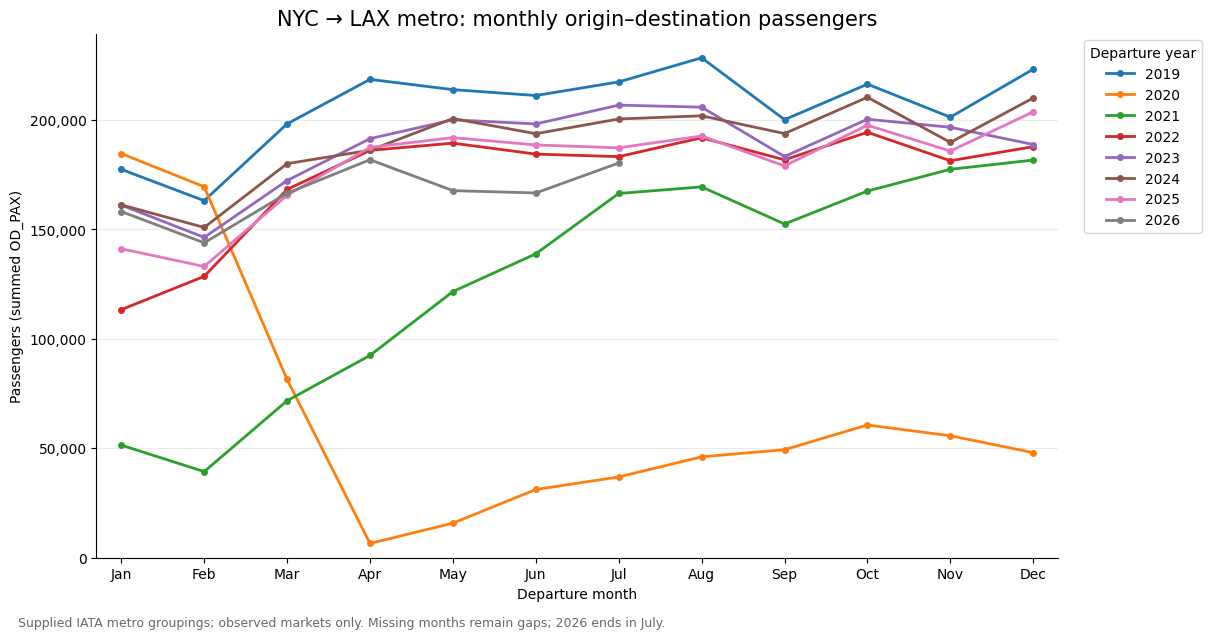

In [5]:
import calendar
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Use the supplied IATA metro groupings, in one direction only.
origin_metro, destination_metro = "NYC", "LAX"
airport_to_metro = airport_info.set_index("AIRPRT_CD")["CITY_METRO_IATA_CD"]
origin_codes = airport_to_metro.index[airport_to_metro.eq(origin_metro)]
destination_codes = airport_to_metro.index[airport_to_metro.eq(destination_metro)]
metro_pair_data = pax_forecasting.loc[
    pax_forecasting["ORG_AIRPRT"].isin(origin_codes)
    & pax_forecasting["DES_AIRPRT"].isin(destination_codes)
].copy()

# Sum observed airport-pair records; absent records are not filled with zero.
metro_month_totals = metro_pair_data.groupby(["DEP_MONTH", "DEP_YEAR"])["OD_PAX"].sum(min_count=1)
metro_monthly_pax = (
    metro_month_totals.unstack("DEP_YEAR")
    .reindex(index=range(1, 13))
    .sort_index(axis=1)
)

# Show the airports actually represented, which can differ from the full lookup.
print(f"{origin_metro} origins in passenger data: {', '.join(sorted(metro_pair_data['ORG_AIRPRT'].unique()))}")
print(f"{destination_metro} destinations in passenger data: {', '.join(sorted(metro_pair_data['DES_AIRPRT'].unique()))}")
print("Totals cover observed records only; absent component pairs may affect coverage.")

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
colors = plt.get_cmap("tab10").colors
for i, year in enumerate(metro_monthly_pax.columns):
    ax.plot(
        metro_monthly_pax.index, metro_monthly_pax[year],
        color=colors[i % len(colors)], marker="o", markersize=4,
        linewidth=2, label=str(year),
    )
ax.set_title("NYC → LAX metro: monthly origin–destination passengers", fontsize=15)
ax.set_xlabel("Departure month")
ax.set_ylabel("Passengers (summed OD_PAX)")
ax.set_xticks(range(1, 13), list(calendar.month_abbr)[1:])
ax.set_xlim(0.7, 12.3)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Departure year", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.text(0.01, -0.035, "Supplied IATA metro groupings; observed markets only. Missing months remain gaps; 2026 ends in July.", fontsize=9, color="dimgray")
plt.show()


TYS origins in passenger data: TYS
TYO destinations in passenger data: HND, NRT
Totals cover observed records only; absent component pairs may affect coverage.


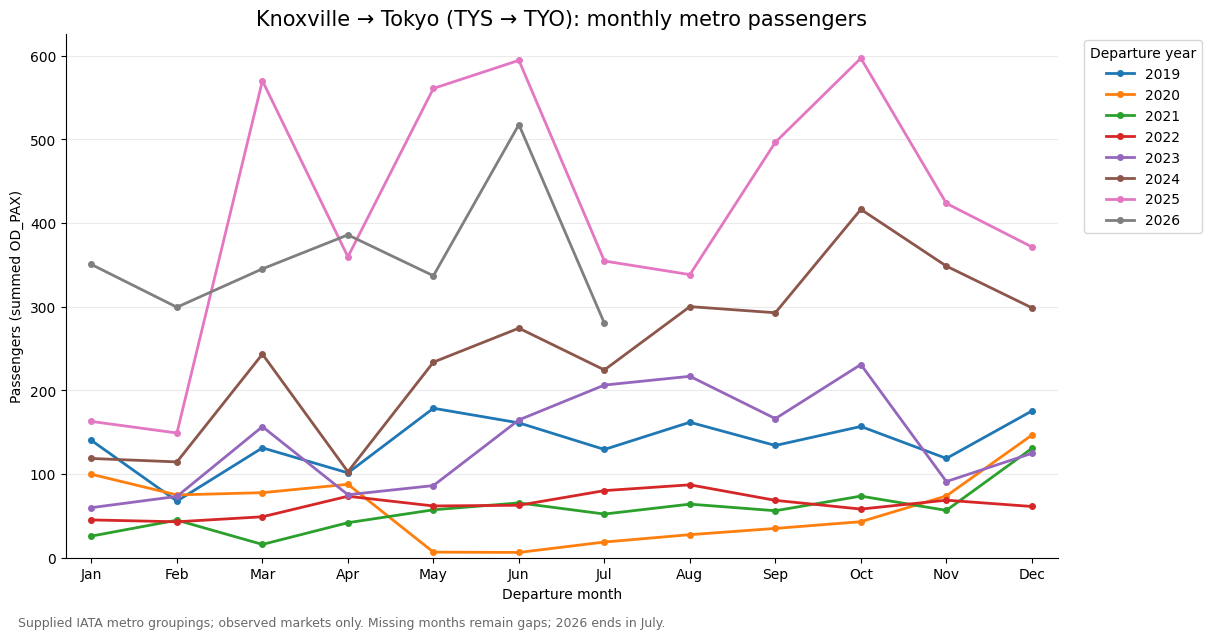

In [6]:
import calendar
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Use the supplied IATA metro groupings, in one direction only.
# Knoxville to Tokyo: about 175 passengers/month, near the lower quartile.
# Selected among multi-airport metro pairs with complete component histories.
origin_metro, destination_metro = "TYS", "TYO"
airport_to_metro = airport_info.set_index("AIRPRT_CD")["CITY_METRO_IATA_CD"]
origin_codes = airport_to_metro.index[airport_to_metro.eq(origin_metro)]
destination_codes = airport_to_metro.index[airport_to_metro.eq(destination_metro)]
metro_pair_data = pax_forecasting.loc[
    pax_forecasting["ORG_AIRPRT"].isin(origin_codes)
    & pax_forecasting["DES_AIRPRT"].isin(destination_codes)
].copy()

# Sum observed airport-pair records; absent records are not filled with zero.
metro_month_totals = metro_pair_data.groupby(["DEP_MONTH", "DEP_YEAR"])["OD_PAX"].sum(min_count=1)
metro_monthly_pax = (
    metro_month_totals.unstack("DEP_YEAR")
    .reindex(index=range(1, 13))
    .sort_index(axis=1)
)

# Show the airports actually represented, which can differ from the full lookup.
print(f"{origin_metro} origins in passenger data: {', '.join(sorted(metro_pair_data['ORG_AIRPRT'].unique()))}")
print(f"{destination_metro} destinations in passenger data: {', '.join(sorted(metro_pair_data['DES_AIRPRT'].unique()))}")
print("Totals cover observed records only; absent component pairs may affect coverage.")

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
colors = plt.get_cmap("tab10").colors
for i, year in enumerate(metro_monthly_pax.columns):
    ax.plot(
        metro_monthly_pax.index, metro_monthly_pax[year],
        color=colors[i % len(colors)], marker="o", markersize=4,
        linewidth=2, label=str(year),
    )
ax.set_title("Knoxville → Tokyo (TYS → TYO): monthly metro passengers", fontsize=15)
ax.set_xlabel("Departure month")
ax.set_ylabel("Passengers (summed OD_PAX)")
ax.set_xticks(range(1, 13), list(calendar.month_abbr)[1:])
ax.set_xlim(0.7, 12.3)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Departure year", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.text(0.01, -0.035, "Supplied IATA metro groupings; observed markets only. Missing months remain gaps; 2026 ends in July.", fontsize=9, color="dimgray")
plt.show()


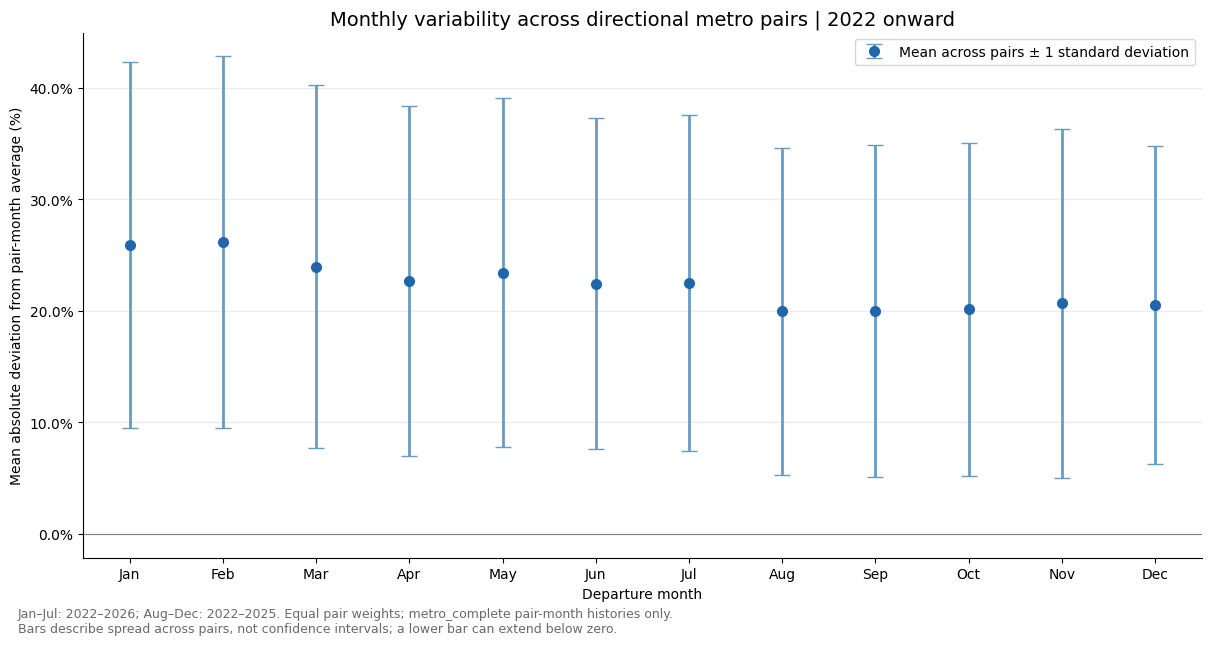

,mean_deviation_pct,std_across_pairs_pct,pair_count,years_per_pair,pairs_with_changing_component_count
DEP_MONTH,,,,,
1,25.92,16.40,15133,5,22
2,26.14,16.68,15082,5,24
3,23.97,16.26,15105,5,13
4,22.68,15.69,15112,5,14
5,23.42,15.64,15184,5,7
6,22.43,14.83,15160,5,38
7,22.50,15.04,15182,5,9
8,19.94,14.63,15178,4,4
9,19.96,14.88,15178,4,16


In [7]:
import calendar
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

# Exclude 2019–2021 before aggregating directional airport pairs to metro pairs.
metro_lookup = airport_info.set_index("AIRPRT_CD")["CITY_METRO_IATA_CD"]
metro_input = pax_forecasting.loc[
    pax_forecasting["DEP_YEAR"] >= 2022,
    ["ORG_AIRPRT", "DES_AIRPRT", "DEP_YEAR", "DEP_MONTH", "OD_PAX"],
].copy()
metro_input["ORG_METRO"] = metro_input["ORG_AIRPRT"].map(metro_lookup)
metro_input["DES_METRO"] = metro_input["DES_AIRPRT"].map(metro_lookup)
if metro_input[["ORG_METRO", "DES_METRO"]].isna().any().any():
    raise ValueError("Some airport codes have no metro mapping; review before aggregating.")

# Sum observed components only. A present metro total can still have missing
# airport-pair components; the coverage table below exposes that limitation.
metro_recent_pax = (
    metro_input.groupby(["ORG_METRO", "DES_METRO", "DEP_YEAR", "DEP_MONTH"])
    ["OD_PAX"].sum(min_count=1).reset_index()
)
metro_pair_month_keys = ["ORG_METRO", "DES_METRO", "DEP_MONTH"]
metro_component_counts = (
    metro_input.groupby(metro_pair_month_keys + ["DEP_YEAR"])
    .size().rename("component_count").reset_index()
)
metro_changing_coverage = (
    metro_component_counts.groupby(metro_pair_month_keys)["component_count"]
    .nunique().gt(1).groupby("DEP_MONTH").sum()
)

# Require every available year for a given calendar month; never fill gaps with zero.
metro_expected_years = metro_recent_pax.groupby("DEP_MONTH")["DEP_YEAR"].nunique()
metro_pair_month_groups = metro_recent_pax.groupby(metro_pair_month_keys)
metro_recent_pax["pair_month_mean"] = metro_pair_month_groups["OD_PAX"].transform("mean")
metro_recent_pax["year_count"] = metro_pair_month_groups["DEP_YEAR"].transform("nunique")
metro_complete = metro_recent_pax["year_count"].eq(metro_recent_pax["DEP_MONTH"].map(metro_expected_years))
metro_eligible = metro_recent_pax.loc[
    metro_complete & (metro_recent_pax["pair_month_mean"] > 0)
    & (metro_recent_pax["year_count"] >= 2)
].copy()

# For each observation: 100 * |passengers - pair/month mean| / pair/month mean.
# Absolute deviations avoid positive and negative differences cancelling out.
metro_eligible["absolute_pct_deviation"] = (
    100 * (metro_eligible["OD_PAX"] - metro_eligible["pair_month_mean"]).abs()
    / metro_eligible["pair_month_mean"]
)
metro_pair_month_deviation = (
    metro_eligible.groupby(metro_pair_month_keys)["absolute_pct_deviation"]
    .mean().rename("mean_absolute_pct_deviation").reset_index()
)

# Each directional pair gets equal weight, regardless of passenger volume.
metro_monthly_deviation_summary = (
    metro_pair_month_deviation.groupby("DEP_MONTH")["mean_absolute_pct_deviation"]
    .agg(mean_deviation_pct="mean", std_across_pairs_pct="std", pair_count="count")
    .reindex(range(1, 13))
)
metro_monthly_deviation_summary["years_per_pair"] = metro_expected_years

metro_monthly_deviation_summary["pairs_with_changing_component_count"] = metro_changing_coverage

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
ax.errorbar(
    metro_monthly_deviation_summary.index,
    metro_monthly_deviation_summary["mean_deviation_pct"],
    yerr=metro_monthly_deviation_summary["std_across_pairs_pct"],
    fmt="o", markersize=7, color="#2166ac", ecolor="#689bc3",
    elinewidth=2, capsize=6,
    label="Mean across pairs ± 1 standard deviation",
)
ax.set_title("Monthly variability across directional metro pairs | 2022 onward", fontsize=14)
ax.set_xlabel("Departure month")
ax.set_ylabel("Mean absolute deviation from pair-month average (%)")
ax.set_xticks(range(1, 13), list(calendar.month_abbr)[1:])
ax.set_xlim(0.5, 12.5)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.axhline(0, color="gray", linewidth=0.8)
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="best")
fig.text(
    0.01, -0.045,
    "Jan–Jul: 2022–2026; Aug–Dec: 2022–2025. Equal pair weights; metro_complete pair-month histories only.\n"
    "Bars describe spread across pairs, not confidence intervals; a lower bar can extend below zero.",
    fontsize=9, color="dimgray",
)
plt.show()

# Coverage diagnostic counts all observed metro pair/month groups, before eligibility filtering.
# Missing component rows are not assumed to mean zero passengers.
display(metro_monthly_deviation_summary.round(2))


Texas origin airports: AUS, DAL, DFW, ELP, HOU, IAH, SAT
California destination airports: BUR, FAT, LAX, LGB, OAK, ONT, PSP, SAN, SFO, SJC, SMF, SNA
Observed airport pairs per month: 82–84 out of 84 distinct pairs across the full period.
Totals cover the supplied markets only; missing component records can affect comparisons.


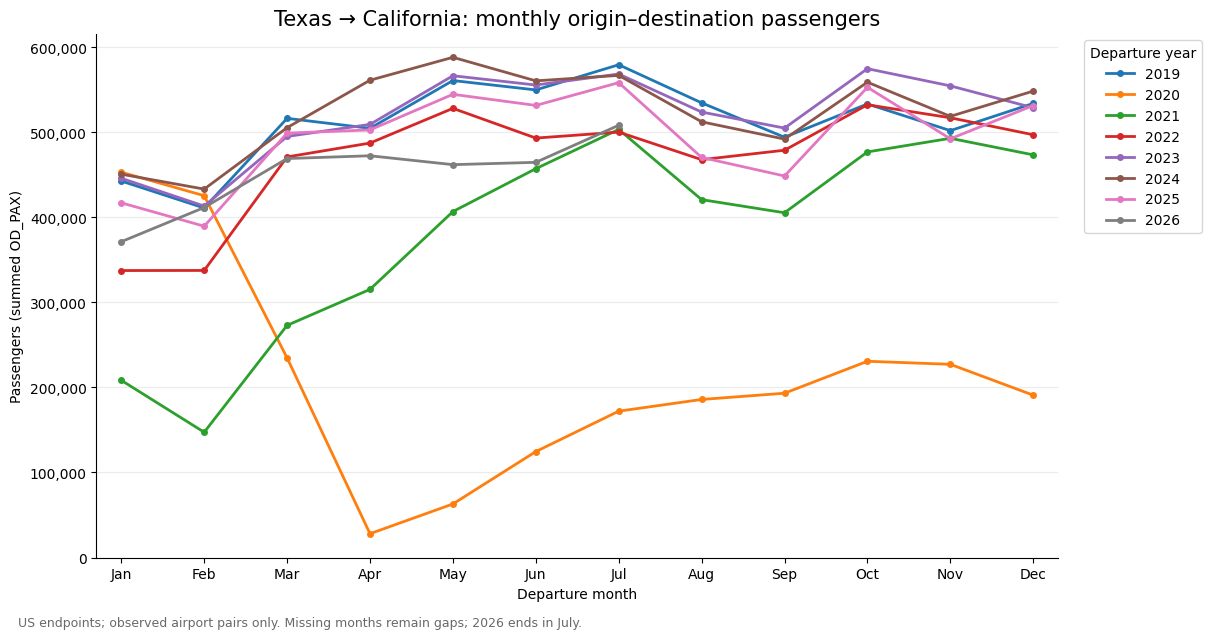

In [8]:
import calendar
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# One direction only, with both endpoints in the US: Texas to California.
origin_state, destination_state = "TX", "CA"
us_airports = airport_info.loc[airport_info["CNTRY_CD"].eq("US")]
tx_codes = us_airports.loc[us_airports["STATE_PROVNC_CD"].eq(origin_state), "AIRPRT_CD"]
ca_codes = us_airports.loc[us_airports["STATE_PROVNC_CD"].eq(destination_state), "AIRPRT_CD"]
state_pair_data = pax_forecasting.loc[
    pax_forecasting["ORG_AIRPRT"].isin(tx_codes)
    & pax_forecasting["DES_AIRPRT"].isin(ca_codes)
].copy()

# Sum the observed component markets. Never replace missing records with zero.
state_monthly_pax = (
    state_pair_data.groupby(["DEP_MONTH", "DEP_YEAR"])["OD_PAX"]
    .sum(min_count=1).unstack("DEP_YEAR")
    .reindex(index=range(1, 13)).sort_index(axis=1)
)

# Coverage is useful when interpreting changes in aggregate demand.
state_component_coverage = (
    state_pair_data.groupby(["DEP_YEAR", "DEP_MONTH"])
    .size().rename("observed_airport_pairs")
)
state_pair_count = state_pair_data[["ORG_AIRPRT", "DES_AIRPRT"]].drop_duplicates().shape[0]
print("Texas origin airports:", ", ".join(sorted(state_pair_data["ORG_AIRPRT"].unique())))
print("California destination airports:", ", ".join(sorted(state_pair_data["DES_AIRPRT"].unique())))
print(f"Observed airport pairs per month: {state_component_coverage.min()}–{state_component_coverage.max()} "
      f"out of {state_pair_count} distinct pairs across the full period.")
print("Totals cover the supplied markets only; missing component records can affect comparisons.")

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
colors = plt.get_cmap("tab10").colors
for i, year in enumerate(state_monthly_pax.columns):
    ax.plot(
        state_monthly_pax.index, state_monthly_pax[year],
        color=colors[i % len(colors)], marker="o", markersize=4,
        linewidth=2, label=str(year),
    )
ax.set_title("Texas → California: monthly origin–destination passengers", fontsize=15)
ax.set_xlabel("Departure month")
ax.set_ylabel("Passengers (summed OD_PAX)")
ax.set_xticks(range(1, 13), list(calendar.month_abbr)[1:])
ax.set_xlim(0.7, 12.3)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Departure year", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.text(0.01, -0.035, "US endpoints; observed airport pairs only. Missing months remain gaps; 2026 ends in July.", fontsize=9, color="dimgray")
plt.show()


Iowa origin airports: DSM
Michigan destination airports: DTW, GRR
Observed airport pairs per month: 2–2 out of 2 distinct pairs across the full period.
Totals cover the supplied markets only; missing component records can affect comparisons.


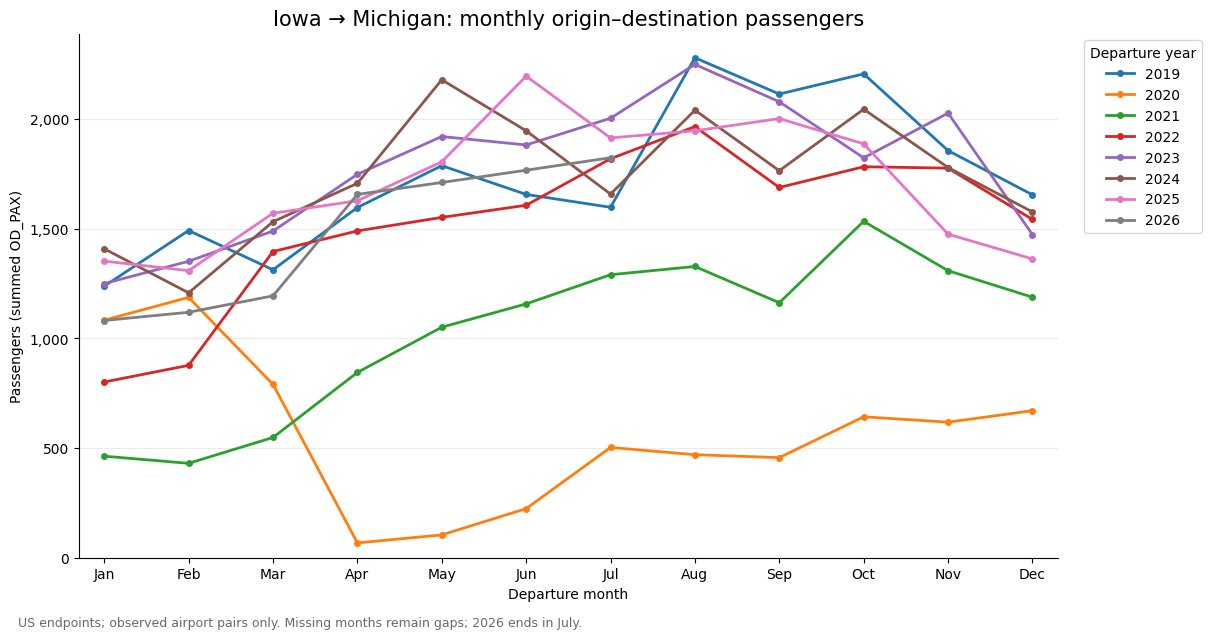

In [9]:
import calendar
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# One direction only, with both endpoints in the US: Iowa to Michigan.
# Near the lower quartile of state-pair mean monthly volume; complete component histories.
origin_state, destination_state = "IA", "MI"
us_airports = airport_info.loc[airport_info["CNTRY_CD"].eq("US")]
ia_codes = us_airports.loc[us_airports["STATE_PROVNC_CD"].eq(origin_state), "AIRPRT_CD"]
mi_codes = us_airports.loc[us_airports["STATE_PROVNC_CD"].eq(destination_state), "AIRPRT_CD"]
state_pair_data = pax_forecasting.loc[
    pax_forecasting["ORG_AIRPRT"].isin(ia_codes)
    & pax_forecasting["DES_AIRPRT"].isin(mi_codes)
].copy()

# Sum the observed component markets. Never replace missing records with zero.
state_monthly_pax = (
    state_pair_data.groupby(["DEP_MONTH", "DEP_YEAR"])["OD_PAX"]
    .sum(min_count=1).unstack("DEP_YEAR")
    .reindex(index=range(1, 13)).sort_index(axis=1)
)

# Coverage is useful when interpreting changes in aggregate demand.
state_component_coverage = (
    state_pair_data.groupby(["DEP_YEAR", "DEP_MONTH"])
    .size().rename("observed_airport_pairs")
)
state_pair_count = state_pair_data[["ORG_AIRPRT", "DES_AIRPRT"]].drop_duplicates().shape[0]
print("Iowa origin airports:", ", ".join(sorted(state_pair_data["ORG_AIRPRT"].unique())))
print("Michigan destination airports:", ", ".join(sorted(state_pair_data["DES_AIRPRT"].unique())))
print(f"Observed airport pairs per month: {state_component_coverage.min()}–{state_component_coverage.max()} "
      f"out of {state_pair_count} distinct pairs across the full period.")
print("Totals cover the supplied markets only; missing component records can affect comparisons.")

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
colors = plt.get_cmap("tab10").colors
for i, year in enumerate(state_monthly_pax.columns):
    ax.plot(
        state_monthly_pax.index, state_monthly_pax[year],
        color=colors[i % len(colors)], marker="o", markersize=4,
        linewidth=2, label=str(year),
    )
ax.set_title("Iowa → Michigan: monthly origin–destination passengers", fontsize=15)
ax.set_xlabel("Departure month")
ax.set_ylabel("Passengers (summed OD_PAX)")
ax.set_xticks(range(1, 13), list(calendar.month_abbr)[1:])
ax.set_xlim(0.7, 12.3)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Departure year", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.text(0.01, -0.035, "US endpoints; observed airport pairs only. Missing months remain gaps; 2026 ends in July.", fontsize=9, color="dimgray")
plt.show()


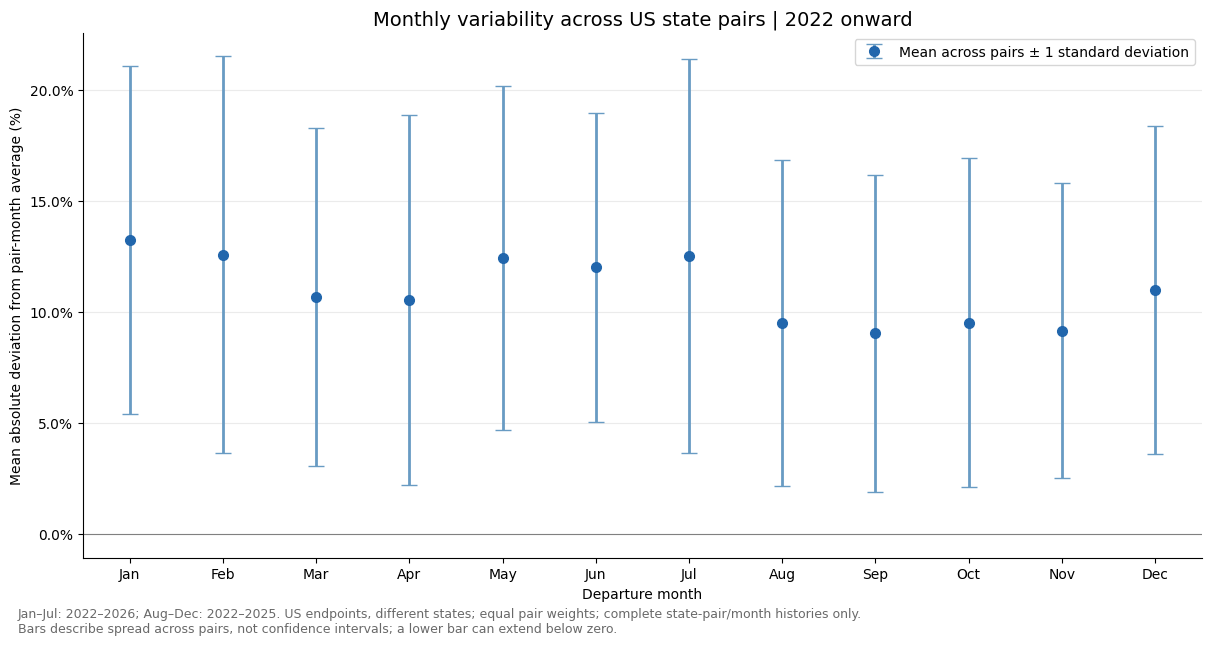

,mean_deviation_pct,std_across_pairs_pct,pair_count,years_per_pair,pairs_with_changing_component_count
DEP_MONTH,,,,,
1,13.23,7.86,1626,5,7
2,12.57,8.93,1628,5,14
3,10.66,7.61,1628,5,10
4,10.54,8.33,1626,5,9
5,12.41,7.75,1627,5,5
6,11.99,6.96,1626,5,24
7,12.51,8.87,1628,5,4
8,9.49,7.36,1628,4,4
9,9.04,7.14,1627,4,9


In [10]:
import calendar
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

# Exclude 2019–2021 before aggregating directional airport pairs to state pairs.
# Restrict both endpoints to country code US, using the supplied state mapping.
us_state_lookup = airport_info.loc[airport_info["CNTRY_CD"].eq("US")].set_index("AIRPRT_CD")["STATE_PROVNC_CD"]
state_input = pax_forecasting.loc[
    (pax_forecasting["DEP_YEAR"] >= 2022)
    & pax_forecasting["ORG_AIRPRT"].isin(us_state_lookup.index)
    & pax_forecasting["DES_AIRPRT"].isin(us_state_lookup.index),
    ["ORG_AIRPRT", "DES_AIRPRT", "DEP_YEAR", "DEP_MONTH", "OD_PAX"],
].copy()
state_input["ORG_STATE"] = state_input["ORG_AIRPRT"].map(us_state_lookup)
state_input["DES_STATE"] = state_input["DES_AIRPRT"].map(us_state_lookup)
if state_input[["ORG_STATE", "DES_STATE"]].isna().any().any():
    raise ValueError("Missing US state mappings; review before aggregating.")
# Between-state travel only; TX → CA and CA → TX remain separate markets.
state_input = state_input.loc[state_input["ORG_STATE"].ne(state_input["DES_STATE"])].copy()

# Sum observed components only. A present state total can still have missing
# airport-pair components; the coverage table below exposes that limitation.
state_recent_pax = (
    state_input.groupby(["ORG_STATE", "DES_STATE", "DEP_YEAR", "DEP_MONTH"])
    ["OD_PAX"].sum(min_count=1).reset_index()
)
state_pair_month_keys = ["ORG_STATE", "DES_STATE", "DEP_MONTH"]
state_component_counts = (
    state_input.groupby(state_pair_month_keys + ["DEP_YEAR"])
    .size().rename("component_count").reset_index()
)
state_changing_coverage = (
    state_component_counts.groupby(state_pair_month_keys)["component_count"]
    .nunique().gt(1).groupby("DEP_MONTH").sum()
)

# Require every available year for a given calendar month; never fill gaps with zero.
state_expected_years = state_recent_pax.groupby("DEP_MONTH")["DEP_YEAR"].nunique()
state_pair_month_groups = state_recent_pax.groupby(state_pair_month_keys)
state_recent_pax["pair_month_mean"] = state_pair_month_groups["OD_PAX"].transform("mean")
state_recent_pax["year_count"] = state_pair_month_groups["DEP_YEAR"].transform("nunique")
state_complete = state_recent_pax["year_count"].eq(state_recent_pax["DEP_MONTH"].map(state_expected_years))
state_eligible = state_recent_pax.loc[
    state_complete & (state_recent_pax["pair_month_mean"] > 0)
    & (state_recent_pax["year_count"] >= 2)
].copy()

# For each observation: 100 * |passengers - pair/month mean| / pair/month mean.
# Absolute deviations avoid positive and negative differences cancelling out.
state_eligible["absolute_pct_deviation"] = (
    100 * (state_eligible["OD_PAX"] - state_eligible["pair_month_mean"]).abs()
    / state_eligible["pair_month_mean"]
)
state_pair_month_deviation = (
    state_eligible.groupby(state_pair_month_keys)["absolute_pct_deviation"]
    .mean().rename("mean_absolute_pct_deviation").reset_index()
)

# Each directional pair gets equal weight, regardless of passenger volume.
state_monthly_deviation_summary = (
    state_pair_month_deviation.groupby("DEP_MONTH")["mean_absolute_pct_deviation"]
    .agg(mean_deviation_pct="mean", std_across_pairs_pct="std", pair_count="count")
    .reindex(range(1, 13))
)
state_monthly_deviation_summary["years_per_pair"] = state_expected_years

state_monthly_deviation_summary["pairs_with_changing_component_count"] = state_changing_coverage

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
ax.errorbar(
    state_monthly_deviation_summary.index,
    state_monthly_deviation_summary["mean_deviation_pct"],
    yerr=state_monthly_deviation_summary["std_across_pairs_pct"],
    fmt="o", markersize=7, color="#2166ac", ecolor="#689bc3",
    elinewidth=2, capsize=6,
    label="Mean across pairs ± 1 standard deviation",
)
ax.set_title("Monthly variability across US state pairs | 2022 onward", fontsize=14)
ax.set_xlabel("Departure month")
ax.set_ylabel("Mean absolute deviation from pair-month average (%)")
ax.set_xticks(range(1, 13), list(calendar.month_abbr)[1:])
ax.set_xlim(0.5, 12.5)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.axhline(0, color="gray", linewidth=0.8)
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="best")
fig.text(
    0.01, -0.045,
    "Jan–Jul: 2022–2026; Aug–Dec: 2022–2025. US endpoints, different states; equal pair weights; complete state-pair/month histories only.\n"
    "Bars describe spread across pairs, not confidence intervals; a lower bar can extend below zero.",
    fontsize=9, color="dimgray",
)
plt.show()

# Coverage diagnostic counts all observed state pair/month groups, before eligibility filtering.
# Uses supplied state codes without geographic corrections. These US-only markets
# differ in scope from the earlier airport/metro charts, which include international travel.
# Missing component rows are not assumed to mean zero passengers.
display(state_monthly_deviation_summary.round(2))
